# Compare neural additive architectures

NAM and NBM both represent a response as a sum of feature effects. NAM learns a separate network for each feature; NBM shares learned basis functions across terms. We will compare their fitted curves, predictive accuracy, and parameter counts, then examine what changes when a transformer contributes a global function of the inputs.


In [1]:
import logging
import warnings
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message="You called.*self.log.*logger=True.*")
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

rng = np.random.default_rng(7)
X = pd.DataFrame({"x": rng.uniform(-1, 1, 900), "z": rng.uniform(-1, 1, 900)})
y = np.sin(3 * X.x) + 0.7 * X.z**2 + rng.normal(0, 0.15, len(X))
X_fit, X_test, y_fit, y_test = train_test_split(X, y, test_size=0.2, random_state=7)
X_train, X_val, y_train, y_val = train_test_split(X_fit, y_fit, test_size=0.25, random_state=8)
fit_options = dict(max_epochs=100, lr=0.01, batch_size=128, patience=15,
                   random_state=7, logger=False, enable_progress_bar=False,
                   enable_model_summary=False, checkpoint_path=tempfile.mkdtemp())


## Fit NAM and NBM

The simulated response is sin(3x) + 0.7z^2 plus Gaussian noise. Its effects are additive, so no interaction is needed to represent the mean.

Both models use the same training, validation, and test rows. We compare test accuracy with the number of trainable parameters to see how sharing basis functions changes the size of the fitted model.

In [2]:
from nampy.models import NAMRegressor, NBMRegressor, NAMformerRegressor

estimators = {
    "NAM": NAMRegressor(layer_sizes=[24, 12], dropout=0., numerical_preprocessing="minmax"),
    "NBM": NBMRegressor(layer_sizes=[16], num_bases=8, nary=[1], dropout=0., bases_dropout=0., numerical_preprocessing="minmax"),
}
rows = []
for name, model in estimators.items():
    model.fit(X_train, y_train, X_val=X_val, y_val=y_val, **fit_options)
    prediction = model.predict(X_test)
    rows.append({"Model": name, "Test R2": r2_score(y_test, prediction)})
# Parameter counts probe representation size, complementing the comparison tutorial.
for row in rows:
    row["Parameters"] = sum(p.numel() for p in estimators[row["Model"]].model.parameters())
(pd.DataFrame(rows)).style.hide(axis="index").format({"Test R2": "{:.3f}", "Parameters": "{:.0f}"})


Model,Test R2,Parameters
NAM,0.954,723
NBM,0.946,237


NAM achieves test R2 of about 0.954 with 723 parameters. NBM reaches about 0.946 with 237 parameters. In this example, shared bases give similar predictive accuracy with roughly one-third as many parameters.


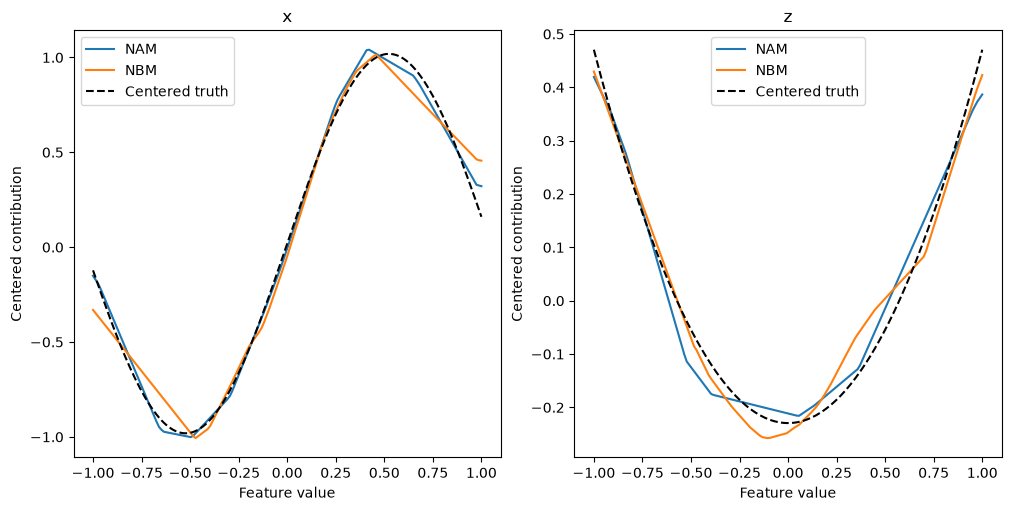

In [3]:
figure, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
for name, model in estimators.items():
    reference = model.predict_components(X_train)
    for axis, feature in zip(axes, X.columns):
        grid = pd.DataFrame({"x": np.zeros(160), "z": np.zeros(160)})
        grid[feature] = np.linspace(-1, 1, 160)
        values = np.asarray(model.predict_components(grid).terms[feature]).reshape(-1)
        values -= np.asarray(reference.terms[feature]).mean()
        axis.plot(grid[feature], values, label=name)
        axis.set(title=feature, xlabel="Feature value", ylabel="Centered contribution")
        axis.set_box_aspect(1)
        axis.legend()
for axis, feature in zip(axes, X.columns):
    values = np.linspace(-1, 1, 160)
    function = (lambda a: np.sin(3*a)) if feature == "x" else (lambda a: .7*a**2)
    axis.plot(values, function(values)-function(X_train[feature].to_numpy()).mean(), "k--", label="Centered truth")
    axis.legend()
plt.show()
plt.close(figure)


Both models recover the sine-shaped x effect and the quadratic z effect. The dashed truth and fitted curves are centered over the same training rows. Differences near the boundaries show where their approximations diverge.


## Inspect a global transformer contribution

NAMformer adds a global transformer function to its feature-specific heads:

$$\eta(x,z)=\beta_0+f_x(x)+f_z(z)+h(x,z).$$

The table identifies the inputs available to each component. The x and z heads each use one feature; global_transformer can use both. All components contribute to the prediction, but the global term cannot be interpreted as the isolated effect of either input. Because it can overlap with the marginal heads, this decomposition need not be unique.


In [4]:
contextual = NAMformerRegressor(d_model=8, n_heads=2, n_layers=1,
                                  transformer_dim_feedforward=16, head_layer_sizes=(),
                                  attn_dropout=0., numerical_preprocessing="minmax")
contextual.fit(X_train, y_train, X_val=X_val, y_val=y_val, **fit_options)
parts = contextual.predict_components(X_test, center=True, reference_X=X_train)
parts.validate_additive_reconstruction(atol=1e-5)
(pd.DataFrame([{"Term": name, "Kind": metadata.kind, "Inputs": ", ".join(metadata.features),
               "Mean absolute contribution": float(np.abs(parts.terms[name]).mean())}
              for name, metadata in parts.term_metadata.items()])).style.hide(axis="index").format(precision=3)


Term,Kind,Inputs,Mean absolute contribution
global_transformer,global,"x, z",0.001
x,main,x,0.507
z,main,z,0.014


The global contribution is small in this fit. The example shows which inputs each component can depend on, but it does not demonstrate a substantial improvement from the transformer. The [interaction-selection tutorial](../tutorials/interaction_selection.rst) examines a dataset with an explicit interaction signal. A small fitted global component on this additive dataset does not imply that the component is unnecessary on other datasets.

## Vary one input at a time

We hold x at 0.2 and vary z across its training range. The x head stays constant because it only receives x. The z head can change, and the global contribution is also allowed to change. This experiment makes the distinction between a marginal head and a global function visible.


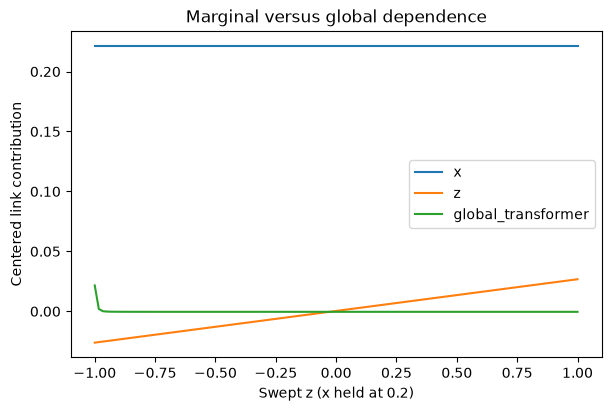

In [5]:
probe = pd.DataFrame({"x": np.full(120, .2), "z": np.linspace(-1, 1, 120)})
probe_parts = contextual.predict_components(probe, center=True, reference_X=X_train)
probe_parts.validate_additive_reconstruction(atol=1e-5)
x_head = np.asarray(probe_parts.terms["x"]).reshape(-1)
figure, axis = plt.subplots(figsize=(6, 4), constrained_layout=True)
for term in ["x", "z", "global_transformer"]:
    axis.plot(probe.z, np.asarray(probe_parts.terms[term]).reshape(-1), label=term)
axis.set(xlabel="Swept z (x held at 0.2)", ylabel="Centered link contribution", title="Marginal versus global dependence")
axis.legend()
plt.show()
plt.close(figure)